In [1]:
import sympy as sp
sp.init_printing()

# Optical and RF/Microwave Sensing: Physics First, then Interpretable Machine Learning

*Colin Casey. Local, reproducible, synthetic-data demonstration.*

## 1. Project scope and safety limits

**What this notebook does:** it builds simple physics models of four kinds of spectral measurement,
generates **synthetic** data from them with fixed seeds, extracts interpretable features, propagates
measurement uncertainty, and classifies the measurements, first with a decision tree, then with a
random forest. It closes with exploratory clustering, MATLAB interoperability, an optional
physics-informed feature model, and an optional, clearly separated quantum-information appendix.

**What it does not do:**
- It has no laboratory data, no experimental results, and no affiliation claims. Every number below comes from code in `src/`.
- Synthetic accuracy doesn't predict real-instrument accuracy, and feature importance doesn't prove causation.
- It gives no hardware safety guidance. Lasers, RF/microwave sources, and high voltage need institutional safety rules and calibrated equipment.

**Supervised vs. unsupervised:** classification (§7–10) *requires labels*. Here they exist because the
data are synthetic. Without labels, only the clustering in §11 applies, and its groups are provisional.

In [2]:
import sys, json, shutil, subprocess
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent     # works from root or notebooks/
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Math
from src import physics_models as pm, synthetic_data as sd, uncertainty as un, classifiers as cl
SEED = 0
FIG, RES, DATA = ROOT / "figures", ROOT / "results", ROOT / "data" / "synthetic"
for d in (FIG, RES, DATA):
    d.mkdir(parents=True, exist_ok=True)
print("versions:", {m.__name__: m.__version__ for m in (np, pd, scipy, matplotlib, sp, sklearn)})

versions: {'numpy': '2.4.4', 'pandas': '2.3.3', 'scipy': '1.17.0', 'matplotlib': '3.10.8', 'sympy': '1.14.0', 'sklearn': '1.8.0'}


## 2. SI units and variable definitions

| symbol | meaning | SI unit |
|---|---|---|
| $\lambda$ | wavelength | m |
| $h$, $c$ | Planck constant (exact), speed of light (exact) | J·s, m/s |
| $E$ | photon energy | J (also shown in eV) |
| $I_0$, $I$ | incident / transmitted irradiance | W/m² |
| $\alpha$, $L$ | absorption coefficient, path length | 1/m, m |
| $R$, $L$, $C$ | resistance, inductance, capacitance | Ω, H, F |
| $f$, $\omega = 2\pi f$ | frequency, angular frequency | Hz, rad/s |
| $Z$, $Z_0$ | impedance, reference impedance (50 Ω) | Ω |
| $\Gamma$ | reflection coefficient | 1 |
| $V$, $P$ | voltage, power | V, W |

Synthetic spectra are sampled on a **normalized axis** $u \in [0, 1)$ (512 points), so features such as
bandwidth and phase slope are in normalized units, which the feature names say.

## 3. SymPy derivations

Each formula used later is derived here, not just quoted.

In [3]:
display(Math(r"\text{Photon energy } (E = hf,\ f = c/\lambda):\quad " + sp.latex(pm.photon_energy_symbolic())))
display(Math(r"\text{Beer–Lambert } (dI/dx = -\alpha I):\quad " + sp.latex(pm.beer_lambert_symbolic())))
display(Math(r"\text{RC charging } (V = RC\,\dot v + v):\quad " + sp.latex(pm.rc_symbolic())))
Z, w0 = pm.rlc_impedance_symbolic()
display(Math(r"\text{Series RLC: } Z = " + sp.latex(Z) + r",\qquad \operatorname{Im}Z = 0 \Rightarrow \omega_0 = " + sp.latex(w0)))
display(Math(r"\text{Power } (P = VI,\ I = V/R):\quad " + sp.latex(pm.power_symbolic())))
print(f"numbers: E(1550 nm) = {float(pm.photon_energy_eV(1550e-9)):.4f} eV;  I/I0 after αL = 1: {float(pm.beer_lambert(1, 100, 0.01)):.4f};  "
      f"P(5 V, 100 Ω) = {float(pm.power_W(5, 100)):.3f} W")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

numbers: E(1550 nm) = 0.7999 eV;  I/I0 after αL = 1: 0.3679;  P(5 V, 100 Ω) = 0.250 W


## 4. Synthetic optical and RF/microwave measurements

Four clearly labeled synthetic classes, each with randomized parameters and a random noise level per
measurement (so the signal-to-noise ratio varies from shot to shot):

| class | model |
|---|---|
| `optical-continuous` | smooth thermal-like (Planck-shaped) spectrum, weak chirp phase |
| `optical-line-spectrum` | 3–6 narrow emission lines on a weak baseline |
| `RF-wideband` | broad flat band with roll-off; linear phase (a pure time delay) |
| `microwave-resonant` | $\lvert S_{11}\rvert$ of a series-RLC resonator vs. 50 Ω: a reflection dip with a phase swing |

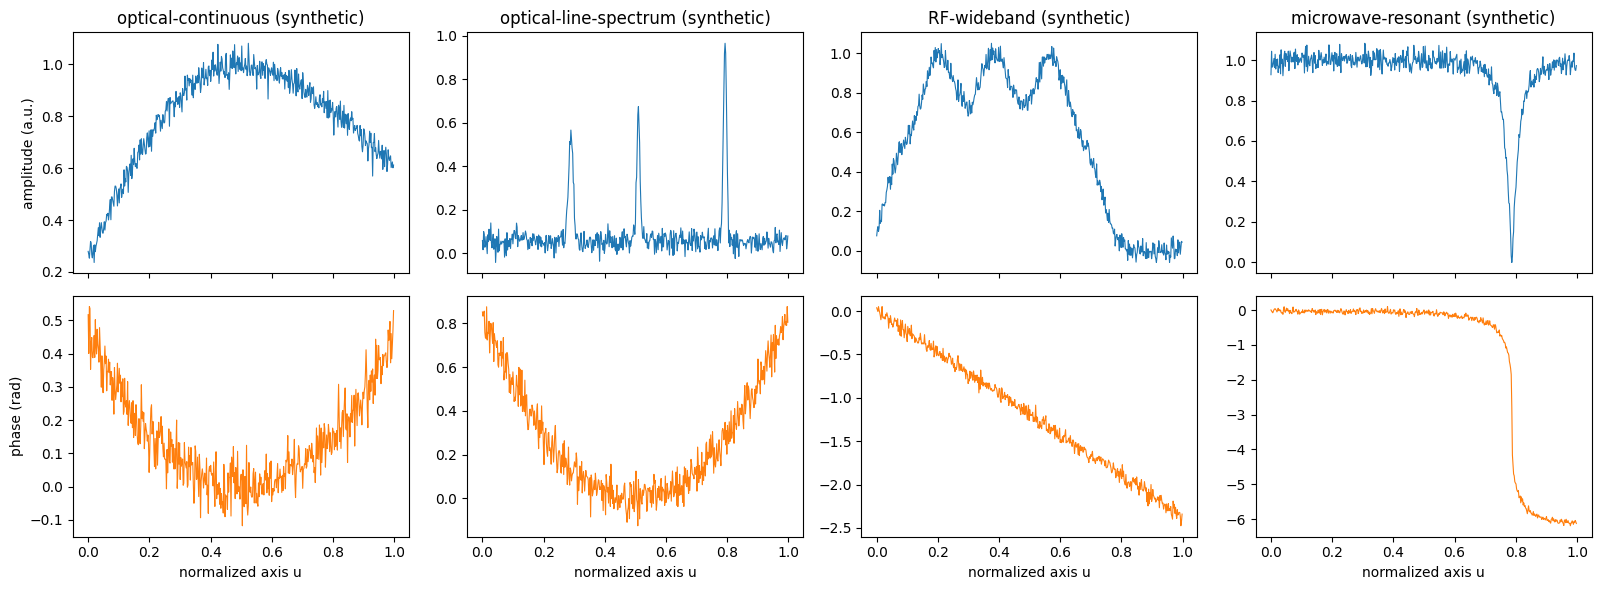

In [4]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharex=True)
u = np.linspace(0, 1, sd.N_POINTS, endpoint=False)
for j, label in enumerate(sd.CLASSES):
    amp, phase = sd.make_measurement(label, rng, sigma_amp=0.03, sigma_phase=0.05)
    axes[0, j].plot(u, amp, lw=0.8); axes[0, j].set_title(label + " (synthetic)")
    axes[1, j].plot(u, np.unwrap(phase), lw=0.8, color="C1")
axes[0, 0].set_ylabel("amplitude (a.u.)"); axes[1, 0].set_ylabel("phase (rad)")
for a in axes[1]: a.set_xlabel("normalized axis u")
plt.tight_layout(); plt.savefig(FIG / "example_spectra.png", dpi=120); plt.show()

## 5. Feature extraction

Seven interpretable features per measurement (`src/synthetic_data.py: extract_features`):

| feature | definition |
|---|---|
| mean intensity | mean of amplitude² |
| peak count | peaks with prominence above 5× the estimated noise |
| bandwidth | span where the smoothed amplitude is ≥ half its maximum |
| phase slope | slope of a linear fit to the unwrapped phase (≈ group delay) |
| amplitude | maximum amplitude |
| SNR (dB) | mean signal power / noise variance (noise from a robust first-difference estimate) |
| return-loss-like (dB) | depth of the deepest dip relative to the median, floored at 3× noise |

In [5]:
X, y, raw = sd.make_dataset(n_per_class=120, seed=SEED)
X.assign(label=y).to_csv(DATA / "synthetic_features.csv", index=False)
print(f"{len(X)} synthetic measurements, {X.shape[1]} features -> {(DATA / 'synthetic_features.csv').relative_to(ROOT)}")
display(X.groupby(y).agg(["mean", "std"]).round(3).T)

480 synthetic measurements, 7 features -> data\synthetic\synthetic_features.csv


label                     RF-wideband  microwave-resonant  optical-continuous  \
mean_intensity      mean        0.507               0.934               0.625   
                    std         0.066               0.047               0.085   
peak_count          mean        2.583               1.908               1.983   
                    std         1.157               1.296               1.037   
bandwidth           mean        0.667               0.996               0.798   
                    std         0.081               0.002               0.096   
phase_slope         mean      -48.639              -2.874               0.055   
                    std        26.918               4.056               0.606   
amplitude           mean        1.350               1.404               1.336   
                    std         0.177               0.194               0.188   
snr_db              mean       14.708              17.870              17.178   
                    std         4.979               4.837               5.230   
return_loss_like_db mean        5.047               7.766               6.068   
                    std         5.151               3.996               3.616   

label                     optical-line-spectrum  
mean_intensity      mean                  0.049  
                    std                   0.018  
peak_count          mean                  4.550  
                    std                   1.383  
bandwidth           mean                  0.512  
                    std                   0.235  
phase_slope         mean                 -0.010  
                    std                   0.047  
amplitude           mean                  1.145  
                    std                   0.161  
snr_db              mean                  6.025  
                    std                   4.388  
return_loss_like_db mean                  0.000  
                    std                   0.000

## 6. Measurement uncertainty and propagation of errors

**Analytic, first order.** For independent inputs, $\sigma_f^2 = \sum_i (\partial f/\partial x_i)^2\sigma_i^2$. For $P = V^2/R$:

In [6]:
P_, sP_, rel, (V, R, sV, sR) = un.power_uncertainty_symbolic()
display(Math(r"\sigma_P = " + sp.latex(sP_) + r",\qquad \frac{\sigma_P}{P} = " + sp.latex(rel)))
P0, sP0 = un.power_uncertainty(5.0, 0.05, 100.0, 1.0)
mP, sPmc = un.power_uncertainty_mc(5.0, 0.05, 100.0, 1.0)
print(f"V = 5.00 ± 0.05 V, R = 100 ± 1 Ω:  first-order P = {P0:.4f} ± {sP0:.5f} W;  Monte Carlo {mP:.4f} ± {sPmc:.5f} W")

<IPython.core.display.Math object>

V = 5.00 ± 0.05 V, R = 100 ± 1 Ω:  first-order P = 0.2500 ± 0.00559 W;  Monte Carlo 0.2501 ± 0.00560 W


Voltage enters squared, so its 1% uncertainty contributes 2% to $P$. That dominates the 1% from $R$.

**Feature uncertainty by repeated measurement.** Re-measure *one* underlying signal 50 times with fresh noise:

In [7]:
rep = un.feature_repeatability(sd.make_measurement, sd.extract_features, "microwave-resonant", n_repeats=50,
                               seed=SEED, sigma_amp=0.05, sigma_phase=0.1)
display(pd.DataFrame(rep, index=["mean", "std over 50 repeats"]).T.round(4))

,mean,std over 50 repeats
mean_intensity,0.8738,0.0036
peak_count,1.3000,1.1294
bandwidth,0.9980,0.0000
phase_slope,-8.6490,0.0143
amplitude,1.1333,0.0169
snr_db,25.4263,0.5113
return_loss_like_db,15.9177,0.5206


Some features are very repeatable (bandwidth, phase slope). Others, like **peak count**, are integers that
can jump with noise. That's one reason the classifiers below are evaluated over many measurements and folds.

## 7. Decision tree (Gini impurity)

The baseline is a shallow decision tree. It splits on the feature threshold that most reduces **Gini
impurity**, $G = 1 - \sum_k p_k^2$.

**Leakage control:** the data are split into training and test sets *first*. Scaling lives inside a
`Pipeline`, so in cross-validation it's re-fit on each training fold only. (Trees don't need scaling;
the pipeline shows the safe pattern for when other models do.)

In [8]:
Xtr, Xte, ytr, yte = cl.split(X, y)
labels = list(sd.CLASSES)
tree = cl.decision_tree(max_depth=3)
r_tree = cl.evaluate(tree, Xtr, Xte, ytr, yte, labels)
lo, hi = un.bootstrap_ci(yte, r_tree["pred"], lambda a, b: np.mean(a == b))
print(f"train {len(Xtr)} / test {len(Xte)} (stratified, seed {SEED})")
print(f"decision tree: accuracy {r_tree['accuracy']:.3f} (95% bootstrap CI {lo:.3f}–{hi:.3f}), balanced accuracy {r_tree['balanced_accuracy']:.3f}")
print(f"5-fold CV on the training set: balanced accuracy {r_tree['cv_mean']:.3f} ± {r_tree['cv_std']:.3f}")

train 336 / test 144 (stratified, seed 0)
decision tree: accuracy 1.000 (95% bootstrap CI 1.000–1.000), balanced accuracy 1.000
5-fold CV on the training set: balanced accuracy 0.994 ± 0.013


## 8. Tree visualization and readable rules

if mean_intensity <= 0.226:
|   --> optical-line-spectrum
else:  # mean_intensity > 0.226
|   if bandwidth <= 0.957:
|   |   if phase_slope <= -1.041:
|   |   |   --> RF-wideband
|   |   else:  # phase_slope > -1.041
|   |   |   --> optical-continuous
|   else:  # bandwidth > 0.957
|   |   --> microwave-resonant


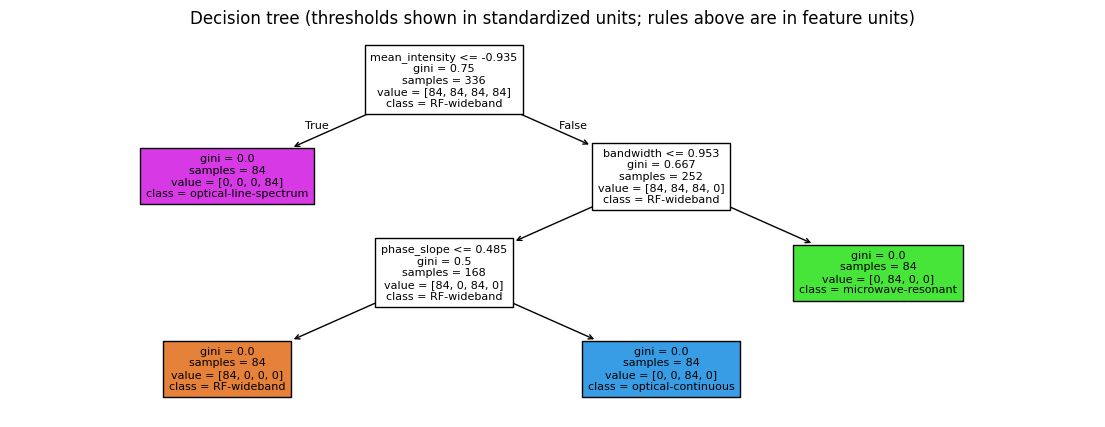

In [9]:
from sklearn.tree import plot_tree
print(cl.tree_rules_physical_units(tree, list(X.columns)))
fig, ax = plt.subplots(figsize=(14, 5))
plot_tree(tree[-1], feature_names=list(X.columns), class_names=list(tree[-1].classes_), filled=True, impurity=True, fontsize=8, ax=ax)
ax.set_title("Decision tree (thresholds shown in standardized units; rules above are in feature units)")
plt.savefig(FIG / "decision_tree.png", dpi=120, bbox_inches="tight"); plt.show()

The rules read like physics: line spectra have low mean intensity (their energy sits in a few narrow lines),
a pure delay shows up as a steep phase slope (RF wideband), and a resonator reflects across almost the
whole band (wide bandwidth). On these synthetic classes, a depth-3 tree already separates the classes
completely.

## 9. Random forest comparison

A random forest averages many trees, each trained on bootstrap samples and random feature subsets.

In [10]:
forest = cl.random_forest()
r_rf = cl.evaluate(forest, Xtr, Xte, ytr, yte, labels)
print(pd.DataFrame({"decision tree": [r_tree["accuracy"], r_tree["balanced_accuracy"], r_tree["cv_mean"], r_tree["cv_std"]],
                    "random forest": [r_rf["accuracy"], r_rf["balanced_accuracy"], r_rf["cv_mean"], r_rf["cv_std"]]},
                   index=["test accuracy", "test balanced accuracy", "CV balanced acc (mean)", "CV balanced acc (std)"]).round(3))

                        decision tree  random forest
test accuracy                   1.000          1.000
test balanced accuracy          1.000          1.000
CV balanced acc (mean)          0.994          0.994
CV balanced acc (std)           0.013          0.013


Both are essentially perfect here, because the four synthetic classes have physically distinct
shapes. An honest stress test is to raise the noise until they start to fail:

,amplitude noise σ,tree balanced acc,forest balanced acc
0,0.1,1.000,1.000
1,0.3,0.942,0.950
2,0.5,0.933,0.942
3,0.8,0.942,0.933
4,1.2,0.875,0.900


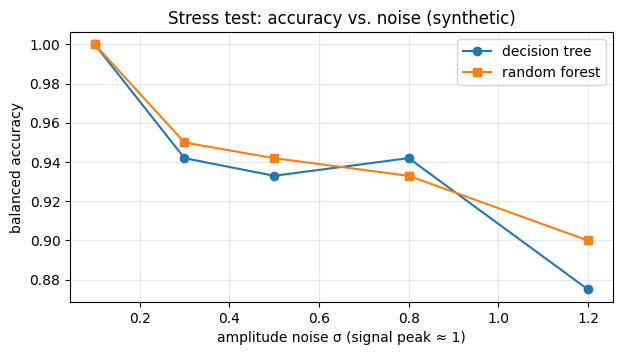

In [11]:
rows = []
for s in (0.1, 0.3, 0.5, 0.8, 1.2):
    Xs, ys, _ = sd.make_dataset(100, seed=SEED, sigma_amp=s, sigma_phase=3*s)
    a, b, c, d = cl.split(Xs, ys)
    rows.append({"amplitude noise σ": s,
                 "tree balanced acc": cl.evaluate(cl.decision_tree(), a, b, c, d, labels)["balanced_accuracy"],
                 "forest balanced acc": cl.evaluate(cl.random_forest(), a, b, c, d, labels)["balanced_accuracy"]})
stress = pd.DataFrame(rows).round(3); display(stress)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(stress["amplitude noise σ"], stress["tree balanced acc"], "o-", label="decision tree")
ax.plot(stress["amplitude noise σ"], stress["forest balanced acc"], "s-", label="random forest")
ax.set(xlabel="amplitude noise σ (signal peak ≈ 1)", ylabel="balanced accuracy", title="Stress test: accuracy vs. noise (synthetic)")
ax.legend(); ax.grid(alpha=0.3); plt.savefig(FIG / "noise_stress_test.png", dpi=120); plt.show()

## 10. Confusion matrix, balanced accuracy, cross-validation, feature importance

These are evaluated on a noisier dataset (σ = 0.8), where the models make mistakes worth inspecting.

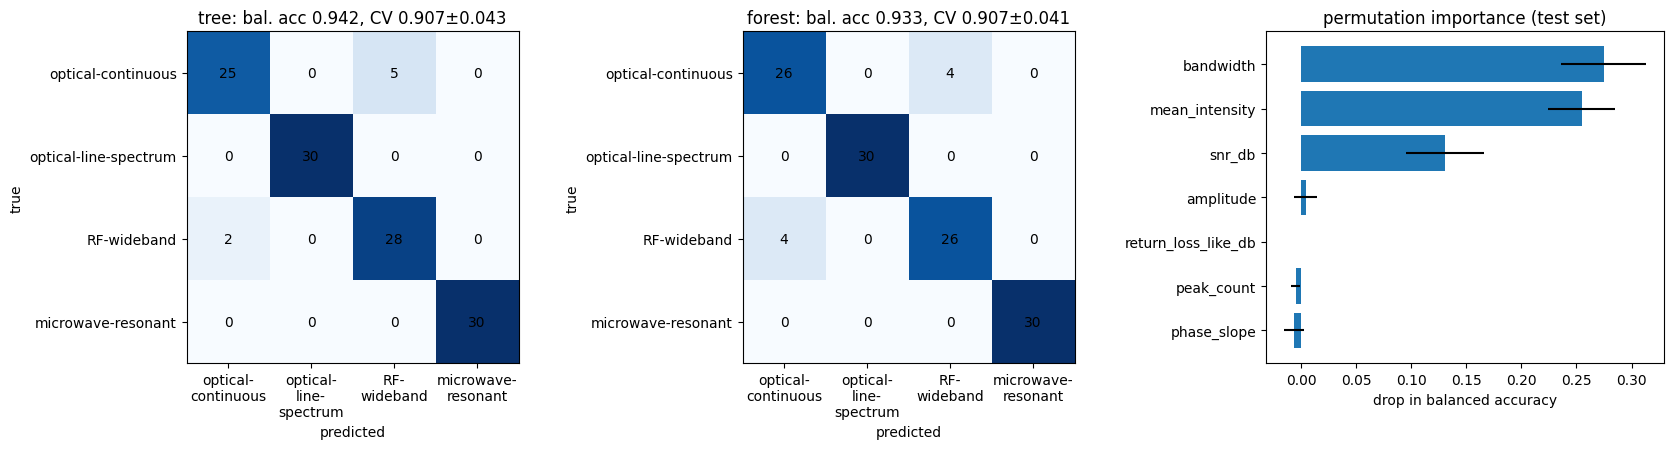

In [12]:
from sklearn.inspection import permutation_importance
Xn, yn, _ = sd.make_dataset(100, seed=SEED, sigma_amp=0.8, sigma_phase=2.4)
a, b, c, d = cl.split(Xn, yn)
res = {"tree": cl.evaluate(cl.decision_tree(), a, b, c, d, labels), "forest": cl.evaluate(rf_n := cl.random_forest(), a, b, c, d, labels)}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, (name, r) in zip(axes[:2], res.items()):
    ax.imshow(r["confusion"], cmap="Blues")
    ax.set(xticks=range(4), yticks=range(4), xticklabels=[l.replace("-", "-\n") for l in labels], yticklabels=labels,
           xlabel="predicted", ylabel="true", title=f"{name}: bal. acc {r['balanced_accuracy']:.3f}, CV {r['cv_mean']:.3f}±{r['cv_std']:.3f}")
    for i in range(4):
        for j in range(4): ax.text(j, i, r["confusion"][i, j], ha="center", va="center")
pi = permutation_importance(rf_n, b, d, n_repeats=20, random_state=SEED, scoring="balanced_accuracy")
order = np.argsort(pi.importances_mean)
axes[2].barh(np.array(Xn.columns)[order], pi.importances_mean[order], xerr=pi.importances_std[order])
axes[2].set(title="permutation importance (test set)", xlabel="drop in balanced accuracy")
plt.tight_layout(); plt.savefig(FIG / "confusion_and_importance.png", dpi=120); plt.show()
json.dump({k: {m: v for m, v in r.items() if m in ("accuracy", "balanced_accuracy", "cv_mean", "cv_std")} for k, r in res.items()},
          open(RES / "metrics_noisy.json", "w"), indent=2)

**Reading feature importance correctly:** permutation importance measures how much *this model* relies
on a feature for *this synthetic data*. It doesn't show that the feature causes the class, and correlated
features can share or swap importance.

## 11. Label-free K-means exploratory clustering

If no labels exist, clustering can suggest structure. The resulting groups are **provisional**: they need
physical interpretation and validation before they mean anything. Comparing them with the true labels
(adjusted Rand index) is only possible here because the data are synthetic.

In [13]:
clusters = cl.kmeans_explore(X, k=4)
ct = pd.crosstab(pd.Series(clusters, name="provisional cluster"), y)
display(ct)
print(f"adjusted Rand index vs the (normally unknown) synthetic labels: {cl.cluster_agreement(y, clusters):.3f}   (1 = identical, 0 = chance)")

label,RF-wideband,microwave-resonant,optical-continuous,optical-line-spectrum
provisional cluster,,,,
0,83,0,0,0
1,11,70,63,0
2,1,0,0,120
3,25,50,57,0


adjusted Rand index vs the (normally unknown) synthetic labels: 0.494   (1 = identical, 0 = chance)


## 12. MATLAB CSV interoperability

Python exports the features. MATLAB's reference script recomputes the deterministic physics quantities and
exports them, and Python reads that CSV and compares.

In [14]:
X.assign(label=y).to_csv(RES / "features_for_matlab.csv", index=False)
print("exported", (RES / "features_for_matlab.csv").relative_to(ROOT))
mfile, csv = ROOT / "matlab" / "optical_rf_reference.m", RES / "matlab_reference_features.csv"
if not csv.exists() and shutil.which("matlab"):
    subprocess.run(["matlab", "-batch", "run('matlab/optical_rf_reference.m')"], cwd=ROOT, check=False)
if csv.exists():
    m = pd.read_csv(csv).set_index("quantity")["value"]
    py = pd.Series(pm.reference_features())
    cmp_ = pd.DataFrame({"MATLAB": m[py.index], "Python": py, "rel. difference": (m[py.index] - py).abs() / py.abs().clip(lower=1e-300)})
    display(cmp_)
    print(f"max relative difference: {cmp_['rel. difference'].max():.2e}")
else:
    print("MATLAB CSV not found. Run:  matlab -batch \"run('matlab/optical_rf_reference.m')\"  from the project root.")

exported results\features_for_matlab.csv


,MATLAB,Python,rel. difference
photon_energy_eV_405nm,3.061338e+00,3.061338e+00,1.450638e-15
photon_energy_eV_532nm,2.330530e+00,2.330530e+00,1.333870e-15
photon_energy_eV_633nm,1.958676e+00,1.958676e+00,1.020282e-15
photon_energy_eV_850nm,1.458638e+00,1.458638e+00,3.196775e-15
photon_energy_eV_1310nm,9.464443e-01,9.464443e-01,1.173046e-16
photon_energy_eV_1550nm,7.998981e-01,7.998981e-01,4.163867e-16
beer_lambert_I_L0m,1.000000e+00,1.000000e+00,0.000000e+00
beer_lambert_I_L0.005m,5.488116e-01,5.488116e-01,1.011479e-15
beer_lambert_I_L0.01m,3.011942e-01,3.011942e-01,3.686070e-16
beer_lambert_I_L0.02m,9.071795e-02,9.071795e-02,1.529773e-16


max relative difference: 2.36e-14


## 13. Optional: a classical physics-informed feature model

Instead of seven generic features, use three chosen from the physics of the sources:
**spectral flatness** (a flat RF band → 1), **group delay** ($-d\phi/d\omega$; a pure delay is linear phase), and
**line fraction** (narrow lines occupy little of the band). This is a classical feature model, with no
neural network or quantum component. Its value is interpretability with fewer inputs, not guaranteed accuracy.

In [15]:
rows = []
for kw, name in (({}, "default (random noise)"), ({"sigma_amp": 0.5, "sigma_phase": 0.3}, "σ_amp = 0.5"), ({"sigma_amp": 0.8, "sigma_phase": 0.3}, "σ_amp = 0.8")):
    Xg, yg, rawg = sd.make_dataset(100, seed=SEED, **kw); Xp, _ = sd.physics_dataset(rawg)
    out = {"noise": name}
    for fname, F in (("7 generic features", Xg), ("3 physics features", Xp)):
        a, b, c, d = cl.split(F, yg); out[fname] = cl.evaluate(cl.decision_tree(), a, b, c, d, labels)["balanced_accuracy"]
    rows.append(out)
display(pd.DataFrame(rows).round(3))

,noise,7 generic features,3 physics features
0,default (random noise),1.0,0.992
1,σ_amp = 0.5,1.0,0.925
2,σ_amp = 0.8,1.0,0.733


At ordinary noise, three physically motivated features almost match seven generic ones. Under heavy
amplitude noise they degrade faster, because spectral flatness is noise-sensitive. "Physics-informed"
is a design choice to test, not a guarantee. For the broader research discussion of combining physics
and machine learning, see the public perspective "Physics-AI Symbiosis" by B. Jalali, A. Kadambi and
V. Roychowdhury (UCLA). It describes three directions: inverse design, nature as a computer, and nature
blended with computers (physics as priors). This notebook's §13 is a small example of the third idea:
physical reasoning chooses the features. This project isn't affiliated with that work. The author list
above is from the paper's own text; check journal, volume, and author details against the published
version before citing.

## 14. Optional QIS appendix (an analogy, not part of the classical model)

**Nothing above uses this section.** The classical pipeline is complete without it. It introduces the
mathematical objects of quantum information science using the same vector and complex-amplitude ideas,
and it does **not** claim that any classical feature vector is a qubit.

- A one-qubit state is a normalized vector of two complex amplitudes, $|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$, with $|\alpha|^2 + |\beta|^2 = 1$.
- Measuring in the $\{|0\rangle, |1\rangle\}$ basis gives outcome 0 with probability $|\alpha|^2$ (the Born rule).
- Measuring in another basis means projecting first: $P(+) = |\langle +|\psi\rangle|^2$.

In [16]:
a_, b_ = sp.symbols("alpha beta", complex=True)
theta, phi = sp.symbols("theta phi", real=True)
psi = sp.Matrix([sp.cos(theta/2), sp.exp(sp.I*phi)*sp.sin(theta/2)])          # general one-qubit state
display(Math(r"|\psi\rangle = " + sp.latex(psi.T) + r"^T,\quad \langle\psi|\psi\rangle = " + sp.latex(sp.simplify((psi.H*psi)[0]))))
plus = sp.Matrix([1, 1]) / sp.sqrt(2)
display(Math(r"P(0) = " + sp.latex(sp.simplify(sp.Abs(psi[0])**2)) + r",\quad P(+) = |\langle +|\psi\rangle|^2 = " + sp.latex(sp.simplify(sp.expand(sp.Abs((plus.H*psi)[0])**2, complex=True)))))
num = {theta: sp.pi/3, phi: sp.pi/4}
p0 = float(sp.Abs(psi[0].subs(num))**2)
shots = np.random.default_rng(SEED).random(10_000) < p0
print(f"example state θ = π/3, φ = π/4: P(0) = {p0:.4f};  10,000 simulated measurements give {shots.mean():.4f}")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

example state θ = π/3, φ = π/4: P(0) = 0.7500;  10,000 simulated measurements give 0.7495


## 15. Limitations and next experiments

**Limitations**
- All data are synthetic, and the four classes are physically distinct by construction, which is why accuracy is high at normal noise.
- Real instruments add calibration drift, nonlinearity, correlated (non-white) noise, and frequency-dependent responses that aren't modeled.
- Each feature's uncertainty is estimated by repetition on synthetic noise, not from an instrument noise budget.
- The physics-informed model is a hand-chosen feature set, not a learned or constrained model.

**Next experiments (with authorized, calibrated data)**
1. Replace `make_dataset` with measured spectra (see README), keeping the same split and pipelines.
2. Build an instrument noise model from repeated dark/background measurements, and re-run §6.
3. Add a held-out *instrument* or *day* split, to test whether models transfer beyond the training conditions.
4. Fit physical models (e.g. a resonator's $f_0$ and $Q$) per measurement and use the fitted parameters, with uncertainties, as features.

In [17]:
print("files written by this notebook:")
for p in sorted(list(FIG.glob("*.png")) + list(RES.glob("*")) + list(DATA.glob("*"))):
    print("  ", p.relative_to(ROOT))

files written by this notebook:
   data\synthetic\synthetic_features.csv
   figures\confusion_and_importance.png
   figures\decision_tree.png
   figures\example_spectra.png
   figures\noise_stress_test.png
   results\features_for_matlab.csv
   results\matlab_reference_features.csv
   results\metrics_noisy.json
